## Middleware

Middleware，也就是**中间件**，是一种控制Agent内部运行过程的技术，它在智能体运行的各个过程中预留钩子（hook），方便我们嵌入自定义操作。

Agent的默认执行流程和中间件嵌入钩子的对比如图：
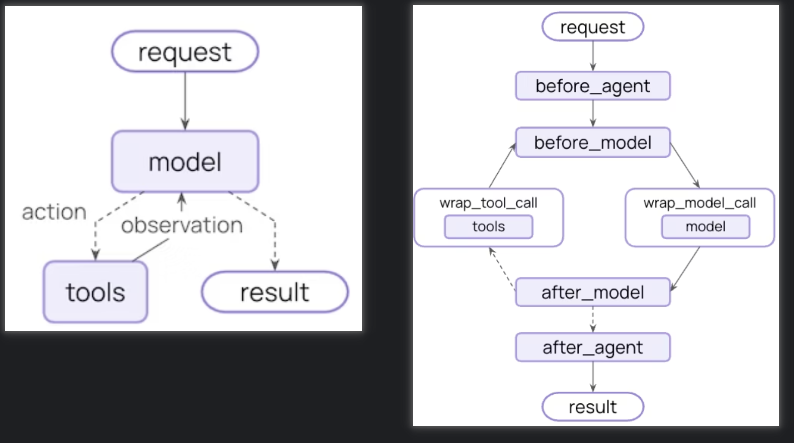
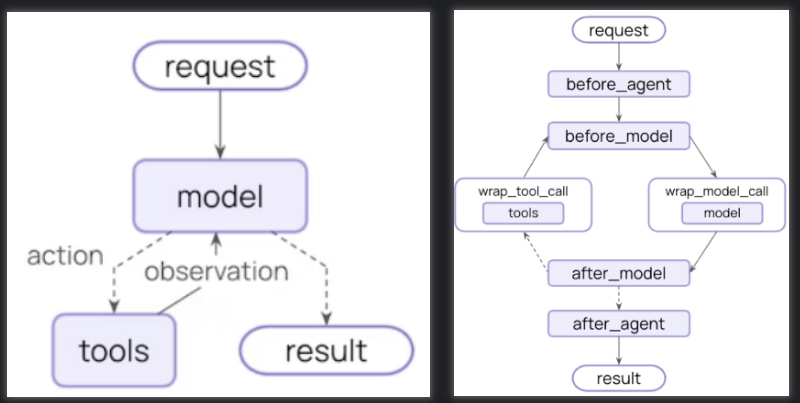

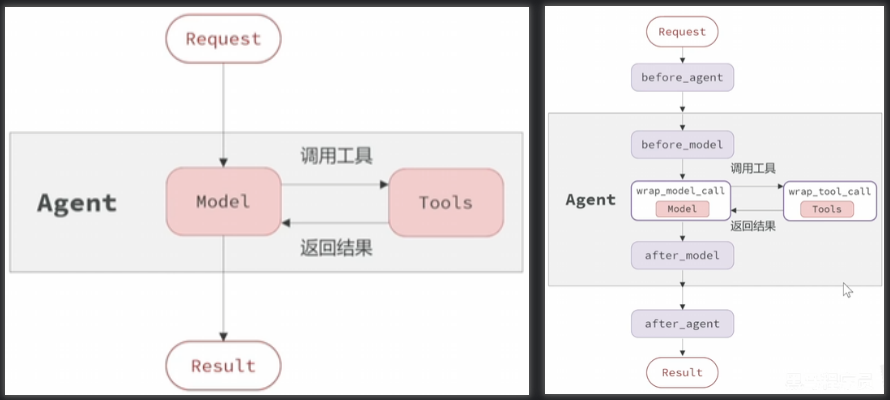

基于Middleware可以实现各种高级功能，比如：
- `拦截和修改请求` - 在模型调用前后对输入输出进行处理
- `实现PII脱敏` - 自动检测和脱敏敏感个人信息
- `会话摘要管理` - 当对话过长时自动压缩历史消息
- `人工审核机制` - 在执行危险操作前等待人工确认
- `动态模型选择` - 根据运行时条件选择不同的模型
- `自定义状态管理` - 扩展Agent状态以跟踪额外信息

In [ ]:
from langchain.agents import create_agent                     # Agent 入口
from langchain.agents.middleware import (                     # 中间件全家桶
    AgentMiddleware,          # 类式中间件的基类
    AgentState,               # agent 状态的类型提示
    ModelRequest,             # 模型请求的封装对象
    ModelResponse,            # 模型响应的类型
    ExtendedModelResponse,    # 带 Command 状态更新的响应
    before_agent, after_agent,    # Node 型：agent 生命周期钩子
    before_model, after_model,    # Node 型：模型调用钩子
    wrap_model_call,              # Wrap 型：包裹模型调用
    wrap_tool_call,               # Wrap 型：包裹工具调用
    dynamic_prompt,               # 便捷型：动态生成 system prompt
)
from langgraph.runtime import Runtime                        # 运行时上下文

### 1. 预定义中间件（Prebuilt Middleware）

LangChain提供了多种预置中间件，可以直接使用。完整内置Middleware列表可以参考官方文档：

[Prebuilt middleware - Docs by LangChain](https://docs.langchain.com/oss/python/langchain/middleware/built-in)

- PIIMiddleware（个人身份信息检测）：检测并处理个人身份信息（PII）
- ModelFallbackMiddleware（模型回退）：当主模型失败时，自动回退到备用模型
- HumanInTheLoopMiddleware（人工审核）：暂停执行，等待人工对工具调用进行审批。

#### 1.1 PIIMiddleware

In [4]:
from langchain.messages import HumanMessage
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware

# =================1.定义PIIMiddleware==========================
# 也可以添加多个PII中间件来检测不同类型的敏感信息
pii_middleware_email = PIIMiddleware(
    "email",
    strategy="redact",  # mask
    apply_to_input=False,
    apply_to_output=True
)

pii_middleware_phone = PIIMiddleware(
    "phone_number",
    # 使用自定义正则表达式
    detector=r"(?:\+?\d{1,3}[\s.-]?)?(?:\(?\d{2,4}\)?[\s.-]?)?\d{3,4}[\s.-]?\d{4}",
    strategy="mask",
    apply_to_input=True
)

# ====================2.在Agent中注册PIIMiddleware================
agent_with_builtin_middleware = create_agent(
    model="deepseek-chat",
    middleware=[pii_middleware_email, pii_middleware_phone]
)

# ======================3.测试=================================
response = agent_with_builtin_middleware.invoke({
    "messages": [
        HumanMessage(
            "我的邮箱是: huge@itcast.cn,我的电话是13698023405,你要记住这些信息，后续要用到。如果记住了请确认一遍。")
    ]
})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

我的邮箱是: huge@itcast.cn,我的电话是****3405,你要记住这些信息，后续要用到。如果记住了请确认一遍。
================================== Ai Message ==================================

好的，我已经记住了您的信息：

- 邮箱：[REDACTED_EMAIL]
- 电话：****3405

后续需要时我会使用这些信息。请您确认是否准确。


### 2. 自定义中间件

[Custom middleware - Docs by LangChain](https://docs.langchain.com/oss/python/langchain/middleware/custom#examples)

#### 2.1 Node-Style hooks
Node-style hooks：在具体某个节点执行的中间件，包含：
- `before_agent`
- `before_model`
- `after_model`
- `after_agent`

例如，我们要实现模型调用计数功能，之前利用 tool 来统计，增加了很多次 tool 调用，浪费token，而且也不太方便。利用中间件就优雅很多。我们可以在每次调用模型后(`after_model`)记录模型调用次数

实现模型调用计数功能
- 定义函数，并用 `@after_model` 装饰器来装饰该函数
- 但是要注意，函数的参数和返回值必须严格按照下面的实例

In [6]:
from langgraph.runtime import Runtime
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import AgentState
from langchain.agents.middleware import after_agent
from langchain.agents import create_agent
from langchain.messages import HumanMessage


class CustomState(AgentState):
    model_call_count: int

@after_agent(state_schema=CustomState)
def model_call_counter_hook(state: CustomState, runtime: Runtime):
    current_count = state.get("model_call_count", 0)
    return {"model_call_count": current_count + 1}

checkpointer=InMemorySaver()

agent = create_agent(
    model="deepseek-chat",
    middleware=[model_call_counter_hook],
    state_schema=CustomState,
    checkpointer=checkpointer
)

config = {"configurable": {"thread_id": "1"}}

# 调用智能体
response = agent.invoke(
    {"messages": [HumanMessage("Hello")],},
    config
)

print(response)

{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='60d17282-a1f5-4742-b1b4-26870e77f2b1'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '4e462dfc-5d7b-42c6-bea6-7749a4a49e99', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a6cc-3bb1-7494-8087-cc7a06627e9f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})], 'model_call_count': 1}


In [7]:
# 调用智能体
response = agent.invoke(
    {"messages": [HumanMessage("Hello")],},
    config
)

print(response)

{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='60d17282-a1f5-4742-b1b4-26870e77f2b1'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '4e462dfc-5d7b-42c6-bea6-7749a4a49e99', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a6cc-3bb1-7494-8087-cc7a06627e9f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}}), HumanMessage(content='Hello', additional_kwargs={}, response_met

#### 2.2 Wrap-Style hooks
- Wrap-style hooks：环绕 model 或 tool 调用的中间件，包括：
  - `wrap_model_call`
  - `wrap_tool_call`



例如，我们来定义一个可以在调用模型时失败重试的中间件，最大重试次数为3次。那就可以使用 `@wrap_model_call`，在模型调用时做出判断，如果失败则重试，重试此时超过3次则结束

同样的，被 `@wrap_model_call` 装饰的函数，其参数和返回值必须严格按照下面的格式：

In [9]:
from langchain.agents.middleware import wrap_model_call, ModelRequest, ModelResponse
from typing import Callable

@wrap_model_call
def retry_model(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
    for attempt in range(3):
        try:
            return handler(request) # 这一步就是调用模型
        except Exception as e:
            print(f"Retry {attempt + 1}/3 after error: {e}")
            if attempt == 2:
                raise
    return None


agent = create_agent(
    model="deepseek-chat",
    middleware=[retry_model]
)

In [11]:
# 调用智能体，并初始化state
response = agent.invoke({"messages": [HumanMessage("Hello")]})
print(response)

{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='bb82f02c-4255-40c4-9e30-808c656e6b57'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '61e3717b-859d-47f9-a6e0-146a28b194ec', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a6d2-e5e5-75ef-a03e-da5278701fbc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})]}


#### 2.3 类装饰器

对于需要同时用到多个hooks的更复杂的中间件逻辑，我们还可以使用自定义类继承AgentMiddleware的方式来创建中间件。

例如，一个用来记录日志的中间件，要在模型调用、工具调用前后记录日志：

In [4]:
from langchain.agents.middleware import AgentMiddleware
from langchain.agents.middleware import ModelRequest, ModelResponse
from langchain.agents import create_agent, AgentState
from langchain.agents.middleware.types import ModelCallResult, ToolCallRequest
from langchain.tools import tool
from langchain.messages import ToolMessage, HumanMessage, AIMessage
from langgraph.types import Command
from langgraph.runtime import Runtime
from typing import Any, Callable
import time

class LoggingMiddleware(AgentMiddleware):
    _start_time: float = 0
    def before_model(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        self._start_time = time.time()          # 用 self 在钩子间共享状态
        print(f"\n=======即将调用模型： {len(state['messages'])} 个消息=======")
        return None

    def after_model(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        print(f"\n=======本次模型调用耗时 {time.time() - self._start_time:.2f}s=======")
        print(f"\n=======模型返回消息: {state['messages'][-1].content}=======")
        return None

    def wrap_model_call(
        self,
        request: ModelRequest,
        handler: Callable[[ModelRequest], ModelResponse],
    ) -> ModelCallResult:
        try:
            print(f"\n=======About to call model with {len(request.messages)} messages=======")
            return handler(request)
        except Exception as e:
            print(f"\n=======[错误]: {str(e)}=======")
            return AIMessage("调用模型失败，请重试~")

    def wrap_tool_call(
        self,
        request: ToolCallRequest,
        handler: Callable[[ToolCallRequest], ToolMessage | Command],
    ) -> ToolMessage | Command:
        print(f"\n=======调用工具: {request.tool_call['name']}=======")
        print(f"\n=======参数: {request.tool_call['args']}=======")
        try:
            result = handler(request)
            print("\n=======工具调用成功！=======")
            return result
        except Exception as e:
            print(f"\n=======工具调用失败: {e}=======")
            raise

@tool
def get_weather(location: str):
    """查询指定城市的天气信息"""
    return f"Current weather in {location} is sunny, 25℃."

agent = create_agent(
    model="deepseek-chat",
    middleware=[LoggingMiddleware()],
    tools=[get_weather],
)

for chunk, metadata in agent.stream(
    {"messages": [HumanMessage("杭州今天天气如何？")]},
    stream_mode="messages"
):
    if chunk and chunk.content:
        print(chunk.content, end="", flush=True)


=======即将调用模型： 1 个消息=======

=======About to call model with 1 messages=======

=======本次模型调用耗时 0.77s=======

=======模型返回消息: =======

=======调用工具: get_weather=======

=======参数: {'location': '杭州'}=======

=======工具调用成功！=======
Current weather in 杭州 is sunny, 25℃.
=======即将调用模型： 3 个消息=======

=======About to call model with 3 messages=======
杭州今天天气晴朗，气温约 25℃，挺舒适的，适合外出活动。需要我帮你查未来几天的天气吗？
=======本次模型调用耗时 0.77s=======

=======模型返回消息: 杭州今天天气晴朗，气温约 25℃，挺舒适的，适合外出活动。需要我帮你查未来几天的天气吗？=======



### 3. 高级用法

中间件除了利用hook做基本的信息记录和判断，还可以有一些高级的用法，例如：
- 动态修改请求：可以拦截发送给模型的请求，动态修改请求中使用的模型、工具、提示词等
- 条件跳转：在满足条件的情况下直接跳转到某个Agent执行的节点

#### 3.1 动态修改请求参数

`@wrap_model_call` 定义的中间件，可以拦截发送给模型的请求，因此我们可以动态修改任意的请求中使用的参数，包括：
- model
- tool
- system_prompt
- ...

关键点是利用 `request.override()` 来覆盖原本的请求参数。

例如，我们定义中间件，可以根据 `context` 中用户的选择来开启或关闭模型的思考模式。

In [5]:
from langchain.agents.middleware import wrap_model_call
from collections.abc import Callable
from pydantic.dataclasses import dataclass

# 定义一个context，记录用户是否开启思考模式
@dataclass
class UserContext:
    thinking: bool = False

@wrap_model_call
def dynamic_model_settings(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse]) -> ModelResponse:

    # 获取上下文参数thinking，是否开启思考模式
    thinking = request.runtime.context.thinking

    # 如果Thinking为True，则开启思考模式，否则关闭思考模式
    thinking_type = "enabled" if thinking else "disabled"
    model_settings = {"extra_body": {"thinking": {"type": thinking_type}}}

    # 覆盖request中的model参数
    modified_request = request.override(model_settings=model_settings)
    return handler(modified_request)

In [6]:
# 创建智能体，设置middleware
agent = create_agent(
    model="deepseek-flash",
    middleware=[dynamic_model_settings],
    context_schema=UserContext
)

# 调用智能体，并初始化state
response = agent.invoke(
    {"messages": [HumanMessage("Hello")]},
    context=UserContext(thinking=False) # 通过Context控制思考模式开关
)

print(response)

{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='4c2e0138-a4b1-434b-82b2-f838090eb696'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '0b6f7865-1500-4751-a5bd-6d79b35e0f8d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a6fe-ba5d-77c6-ad0b-ec18798d793e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})]}


#### 3.2 条件跳转

在中间件使用 `jump_to` 指令可以跳过模型调用，直接进入指定的Agent节点。

例如，我们设定一个模型限流的中间件，当判断用户模型调用次数超过阈值，直接禁止调用，结束Agent运行。

In [9]:
from langgraph.runtime import Runtime
from langgraph.checkpoint.memory import InMemorySaver
from typing import NotRequired, Any
from langchain.agents.middleware import AgentMiddleware, hook_config, AgentState

# 1.定义自定义state，记录模型调用次数
class CustomAgentState(AgentState):
    """扩展Agent状态，添加自定义字段"""
    model_call_count: NotRequired[int]  # 模型调用次数

# 2.定义中间件
class ModelCallLimitMiddleware(AgentMiddleware[CustomAgentState]):
    def __init__(self, max_limit: int = 10):
        super().__init__()
        self.max_limit = max_limit

    # after_model hook，模型调用次数计数
    def after_model(self, state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
        current_count = state.get("model_call_count", 0)
        return {"model_call_count": current_count + 1}

    # before_model hook，校验模型调用次数是否超限
    @hook_config(can_jump_to=["end"])
    def before_model(self, state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
        # 获取模型调用次数
        current_count = state.get("model_call_count", 0) + 1
        # 判断是否超限
        print(f"当前模型调用次数：{current_count}/{self.max_limit}")
        if current_count > self.max_limit:
            return {
                "jump_to": "end",
                "messages": AIMessage(f"模型调用次数超过最大限制：{self.max_limit}！")
            }
        return None

# @before_model(can_jump_to=["end"])
# def check_call_limit(state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
#     pass

In [15]:
# 创建智能体，设置middleware
agent = create_agent(
    model="deepseek-chat",
    middleware=[ModelCallLimitMiddleware(max_limit=2)],
    checkpointer=InMemorySaver(),
    state_schema=CustomAgentState
)
config = {"configurable": {"thread_id": "1"}}

# 调用智能体，并初始化state
response = agent.invoke({
    "messages": [HumanMessage("Hello")],
    "model_call_count": 0,
}, config)

print(response)

当前模型调用次数：1/2
{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='aec4d98b-0ed2-4ae2-853f-6d5675f9967c'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'dfbf51a9-e01e-4e02-aa3e-4e903e588c6d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a70f-4339-773f-9786-6d241dbc54f5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})], 'model_call_count': 1}
